In [43]:
import cv2 as cv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import skimage as ski

import numpy.ma as ma
# import cupy as cp

import scipy as sp

import statistics as st

from itertools import cycle

# from sklearn.preprocessing import minmax_scale
import pandas as pd

from scipy import ndimage as ndi
from skimage.feature import peak_local_max

import mpl_toolkits as mpl

from pathlib import Path

In [44]:
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams['figure.figsize'] = [6.4, 4.9]

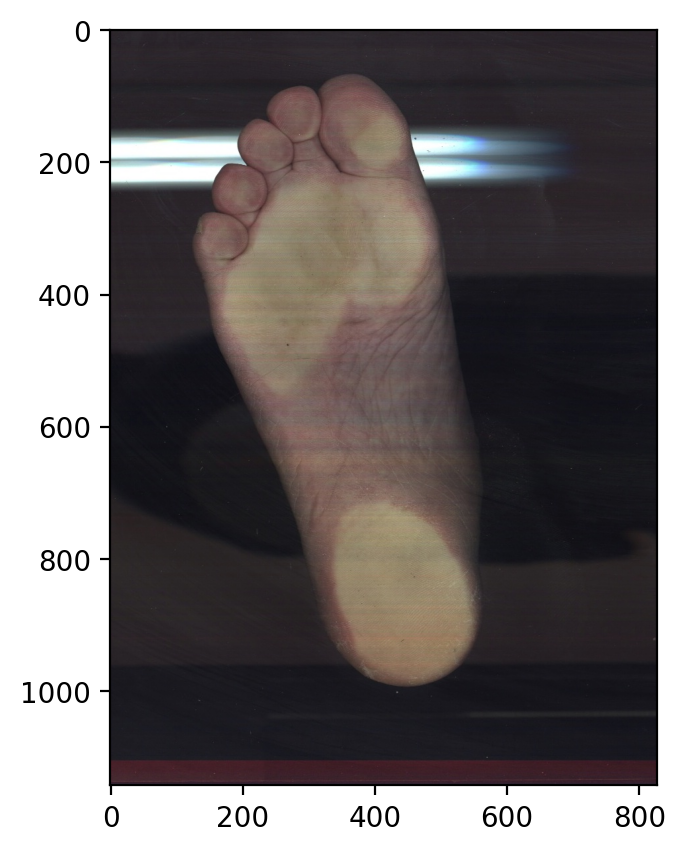

In [61]:
image = cv.imread('../обработка изображений/плантограммы/row1_Сканирование 11_12_photo1.jpg', cv.IMREAD_UNCHANGED)

image = cv.cvtColor(image, cv.COLOR_BGR2RGB)

plt.imshow(image)

In [32]:
def split_foot(image):
    leftPad = 280
    rightPad = 1920 - 1630
    yPad = 50
    assert image.shape == (1080, 1920, 3)
    return image[yPad:,leftPad:880,:], image[yPad:,1025:-rightPad,:]


(1030, 600, 3) (1030, 605, 3)


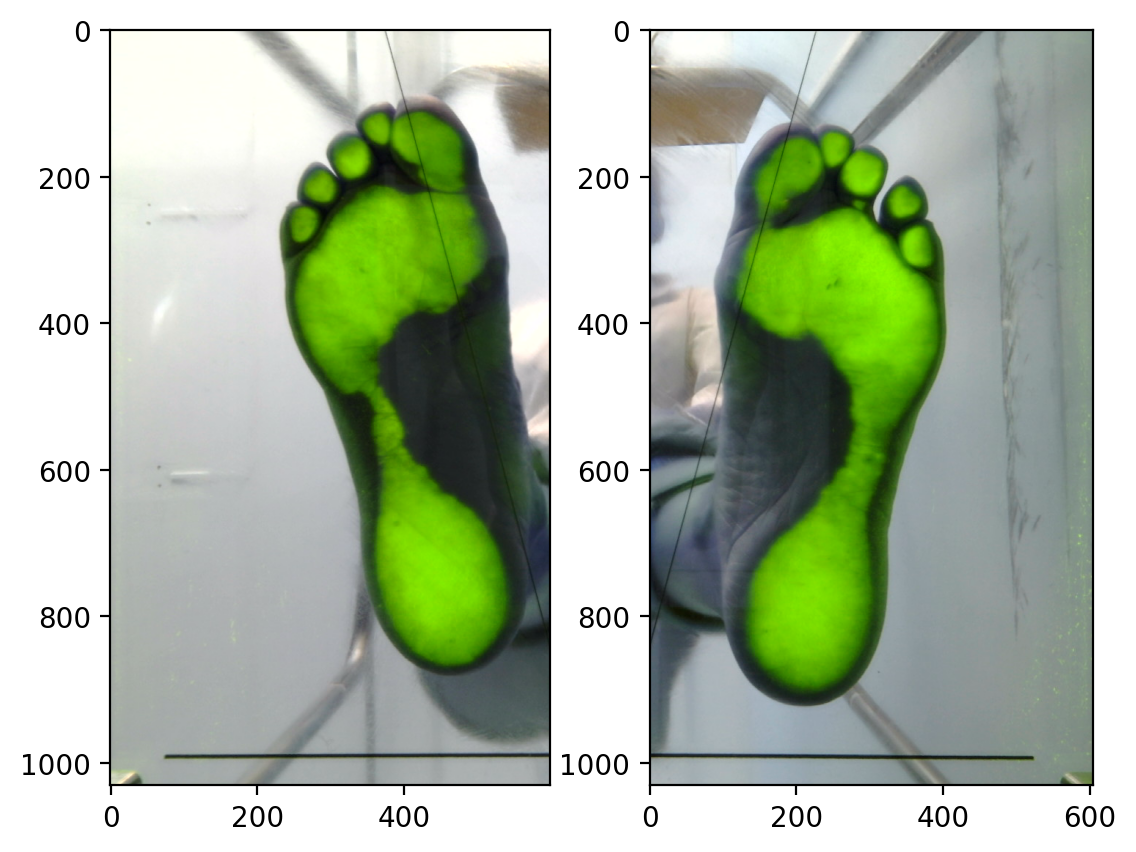

In [33]:
footL, footR = split_foot(image)
fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(footL)
ax2.imshow(footR)
# ax1.grid(which='major')
# ax1.set_yticks(np.linspace(0, 1100, 65), )
print(footL.shape, footR.shape)

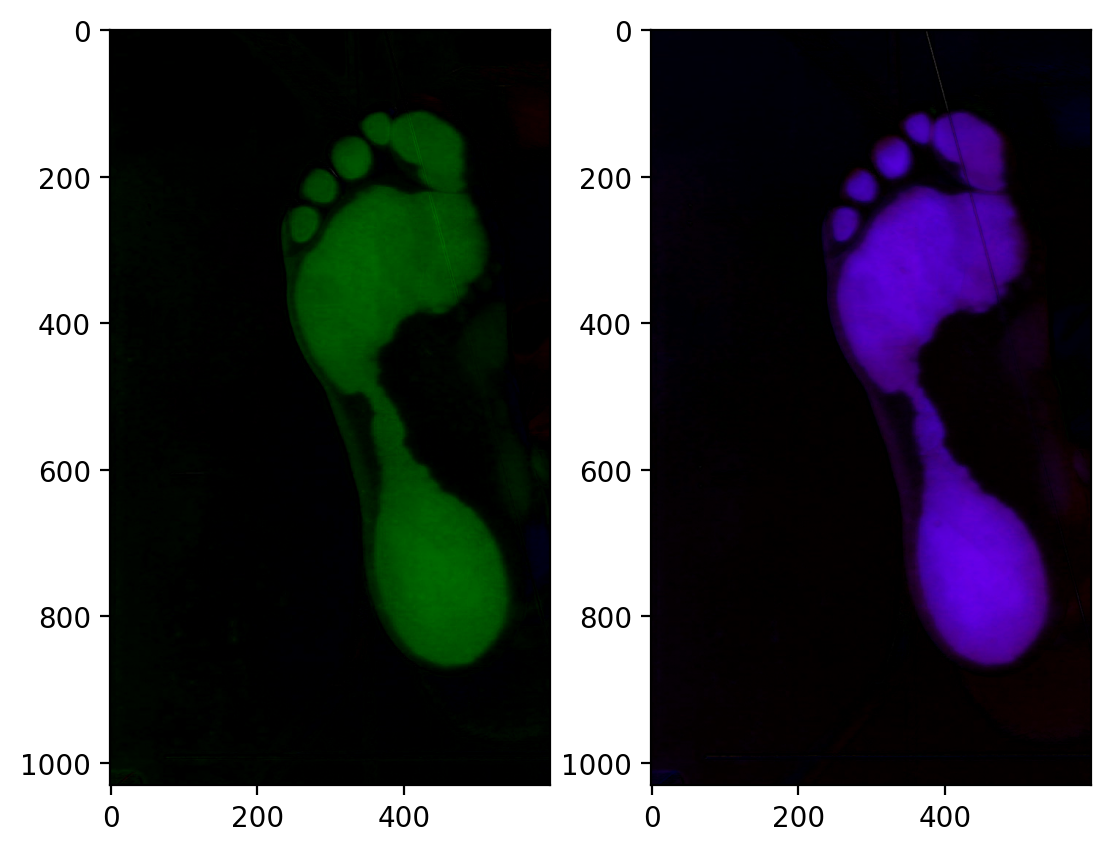

In [34]:
fig, axs = plt.subplots(1, 2)

axs[0].imshow(ski.morphology.white_tophat(footL))

axs[1].imshow(ski.morphology.black_tophat(footL))

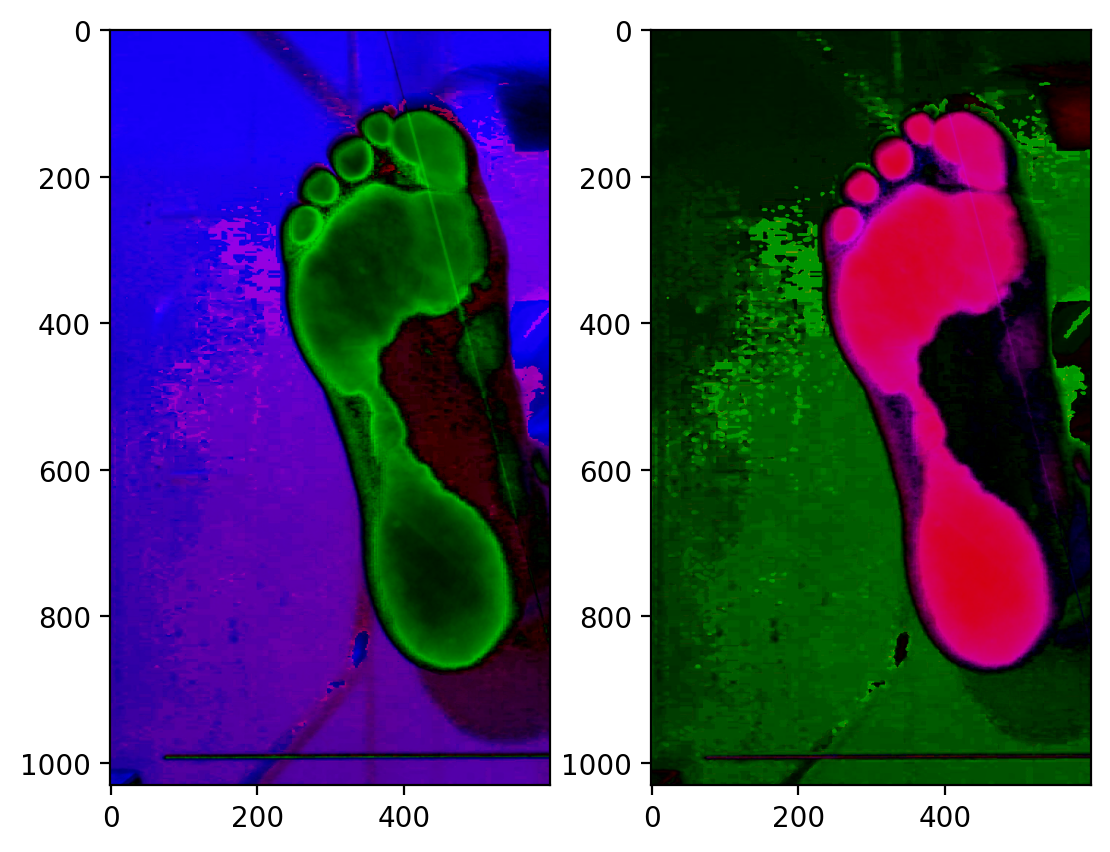

In [35]:
fig, axs = plt.subplots(1, 2)

hsv = cv.cvtColor(footL, cv.COLOR_RGB2HSV)

axs[0].imshow(ski.morphology.white_tophat(hsv))
axs[1].imshow(ski.morphology.black_tophat(hsv))

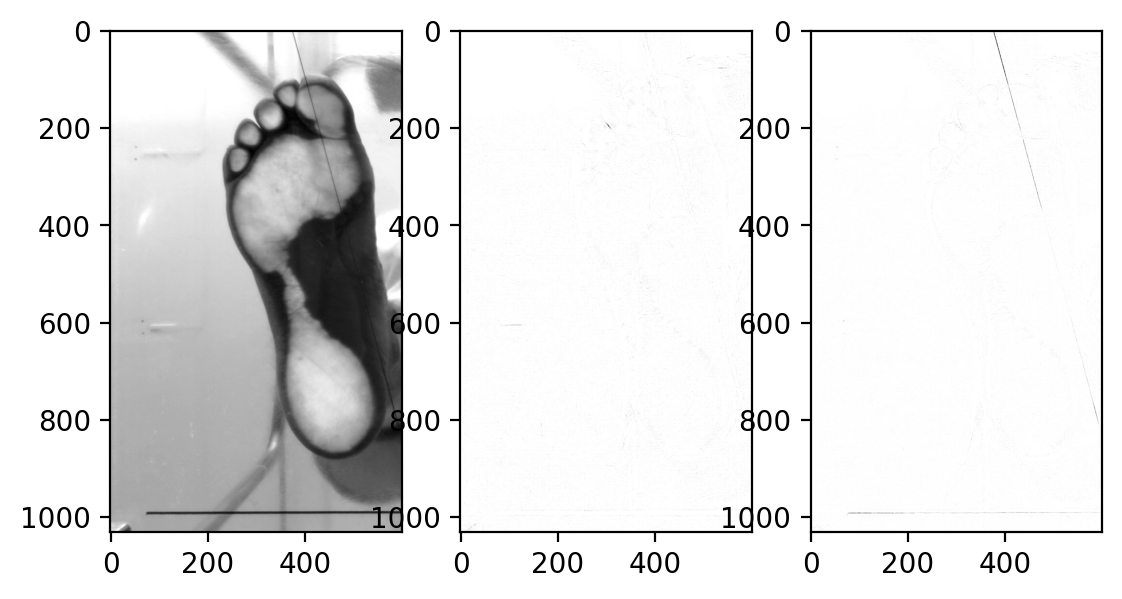

In [37]:
fig, axs = plt.subplots(1, 3)

hsv = cv.cvtColor(footL, cv.COLOR_RGB2HSV)

V = hsv[..., 2]

axs[0].imshow(V, 'gray')
axs[1].imshow(~ski.morphology.white_tophat(V), 'gray')
axs[2].imshow(~ski.morphology.black_tophat(V), 'gray')